# ЛР 4. Случайный лес

## Данные

Avila. По 10 признакам фрагмента текста предсказываем одного из 12 переписчиков. Это помогает распределять фрагменты перед ручной проверкой. Используем разбиение UCI и три стратифицированных фолда в обучающей части. [Источник](https://doi.org/10.24432/C5K02X)

Tasmania. По координатам 16 преобразователей предсказываем мощность фермы. Это позволяет отбирать конфигурации перед запуском симулятора. Мощности отдельных преобразователей исключаем, поскольку их сумма практически равна цели. Берем 7200 конфигураций. Раскладки с одинаковыми координатами после округления до 10 м попадают в одну группу. Группы разделяем между обучением и тестом. В обучающей части три групповых фолда. [Источник](https://doi.org/10.24432/C5831S)

In [1]:
# Загрузка данных и проверка разбиений.
import pandas as pd
from IPython.display import display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 4
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila,20867,10430,10437,10,"Разбиение UCI, 3 стратифицированных фолда на t..."
1,Tasmania,72000,5762,1438,32,"20% групп на тесте, 3 групповых фолда на train."


,Avila
Точных совпадений векторов признаков между train/test,0


,Tasmania
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Метрики

Avila. Macro-F1 дает одинаковый вес каждому классу. Balanced accuracy усредняет полноту по классам. Accuracy показывает общую долю верных ответов.

Tasmania. MAE показывает средний промах в МВт. RMSE сильнее учитывает крупные ошибки. R² сравнивает модель с прогнозом среднего.

Для сравнения простая модель предсказывает самый частый класс или медианную мощность из обучающей выборки.

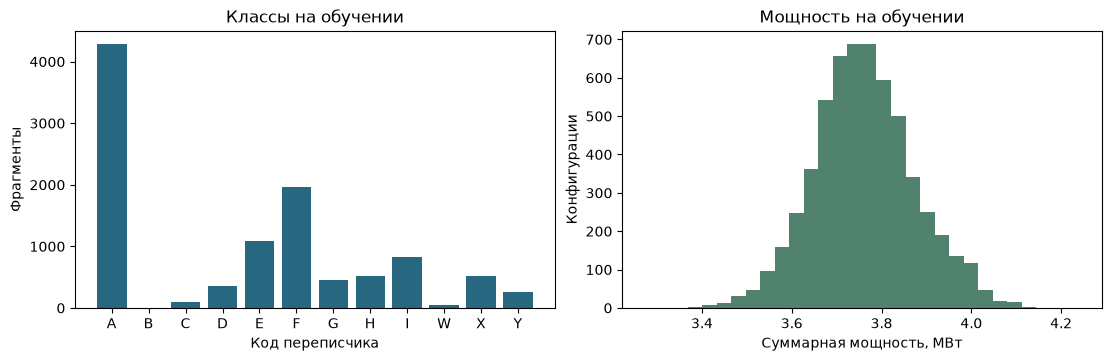

In [2]:
# Распределения классов и мощности на обучающей выборке.
plot_training(tasks)

## Бейзлайн sklearn

Лес sklearn обучает 32 дерева на выборках с возвращением. В каждом узле число случайных признаков примерно равно квадратному корню из общего числа признаков.

## Подбор параметров

Сравниваем 32 и 64 дерева. Большее число деревьев может снизить разброс прогноза. В Avila проверяем веса классов и ограничения дерева. В Tasmania сравниваем координаты, геометрические признаки и их сочетание.

Выбор по среднему macro-F1 или MAE на трех фолдах. Масштабирование обучается внутри каждого фолда. При равенстве оценок берем первый вариант.

In [3]:
# Проверка параметров на трех фолдах.
selections = select_candidates(LAB, tasks)
for task in tasks:
    print(f"{task.title} ({primary_metric(task)})")
    display(selections[task.key][2].round(5))

Avila (macro_f1)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.96474,0.01498,0.94785,0.97000,0.97638,False
1,Взвешивание редких классов,raw,"{""class_weight"": ""balanced""}",0.96310,0.02095,0.96389,0.94177,0.98364,False
2,Глубина 14 и минимум 3 в листе,raw,"{""max_depth"": 14, ""min_samples_leaf"": 3}",0.89762,0.04588,0.84820,0.90581,0.93885,False
3,64 дерева,raw,"{""n_estimators"": 64}",0.97191,0.01056,0.96177,0.97112,0.98284,True


Tasmania (mae_mw)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.05162,0.00030,0.05197,0.05143,0.05147,False
1,Геометрия,geometry,{},0.04974,0.00098,0.04993,0.05062,0.04867,False
2,64 дерева,raw,"{""n_estimators"": 64}",0.05098,0.00064,0.05151,0.05028,0.05117,False
3,Геометрия и ограничения деревьев,geometry,"{""max_depth"": 14, ""min_samples_leaf"": 3}",0.04976,0.00097,0.04980,0.05071,0.04877,False
4,Координаты и геометрия,combined,{},0.04759,0.00058,0.04797,0.04787,0.04693,True


## Результаты sklearn

Начальную и выбранную модели обучаем на всей обучающей выборке и проверяем на тесте.

In [4]:
# Обучение моделей и замер метрик на тесте.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    print(task.title)
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,1.36043,0.18211,0.98152,0.97484,0.98285
2,sklearn tuned,64 дерева,2.69987,0.36134,0.98705,0.98325,0.98659


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,1.59360,0.07211,0.05184,0.06984,0.61304
2,sklearn tuned,Координаты и геометрия,2.28709,0.15122,0.04620,0.06304,0.68479


## Своя реализация

Для каждого CART выбираем строки с возвращением. В каждом узле заново выбираем случайные признаки. Лес усредняет вероятности классов или прогнозы мощности. Порядок классов одинаков во всех деревьях, даже если отдельный класс не попал в выборку дерева.

Для обеих версий используем те же настройки и признаки, что у sklearn. [Код моделей](labkit/models.py)

In [5]:
# Метрики sklearn и собственных моделей.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    print(task.title)
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,1.36043,0.18211,0.98152,0.97484,0.98285
2,sklearn tuned,64 дерева,2.69987,0.36134,0.98705,0.98325,0.98659
3,own baseline,Бейзлайн,9.39830,0.46616,0.98058,0.97307,0.98007
4,own tuned,64 дерева,17.37319,0.56788,0.98378,0.97867,0.98256


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,1.59360,0.07211,0.05184,0.06984,0.61304
2,sklearn tuned,Координаты и геометрия,2.28709,0.15122,0.04620,0.06304,0.68479
3,own baseline,Бейзлайн,24.21804,0.13875,0.05239,0.07102,0.59992
4,own tuned,Координаты и геометрия,23.56517,0.14319,0.04633,0.06338,0.68137


## Ошибки на тесте

Графики для настроенных моделей sklearn. Строки матрицы ошибок показывают доли по истинному классу. Пунктир на графике мощности показывает идеальный прогноз.

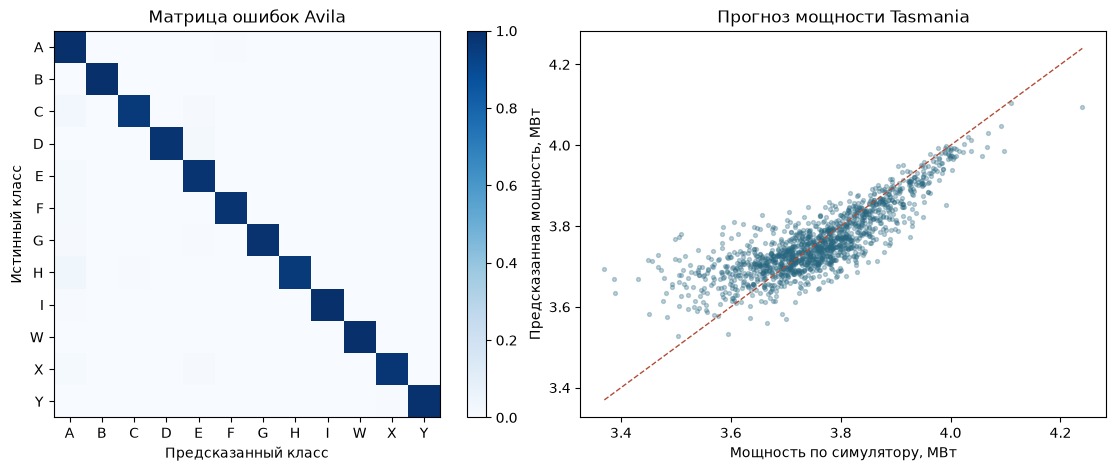

In [6]:
# Матрица ошибок и график прогноза мощности.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Выводы и запись метрик для итоговой таблицы.
print(comparison_text(tasks, results, selections))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

Avila (macro-F1)
По кросс-валидации выбран вариант «64 дерева».
Среднее на фолдах: 0.9647 до настройки и 0.9719 после.
Sklearn на тесте: 0.9815 до настройки и 0.9870 после.
Своя модель на тесте: 0.9806 до настройки и 0.9838 после.
Разница со sklearn на тесте: -0.0009 до настройки и -0.0033 после.

Tasmania (MAE, МВт)
По кросс-валидации выбран вариант «Координаты и геометрия».
Среднее на фолдах: 0.0516 до настройки и 0.0476 после.
Sklearn на тесте: 0.0518 до настройки и 0.0462 после.
Своя модель на тесте: 0.0524 до настройки и 0.0463 после.
Разница со sklearn на тесте: +0.0005 до настройки и +0.0001 после.
Метрики сохранены в results/lab_04.csv
